# Can training weights reduce the color shortcut in a Random Forest?

This follows `RF_bias.ipynb`, using the same raw RGB CMNIST images, digit labels,
color annotations, and existing train/validation/test directories. The intervention
is **only the weight assigned to each training observation**. Tree parameters,
input features, and training observations remain identical across methods.
There is no split-criterion search, image recoloring, or feature removal.

**Research question:** can weighting the rare digit–color combinations make color
less rewarding to the forest and improve accuracy on bias-conflicting digits?
This is spurious-correlation bias, rather than statistical estimator bias or a
demographic fairness claim. Weighting can reduce reliance on a shortcut; it cannot
guarantee that a forest becomes invariant to color.

Run every cell in order. Install `requirements-mitigation.txt` in your notebook
environment first. The default is a reproducible **12,000-image exploratory
training subset**, the entire validation set, and the entire test set. Set
`TRAIN_LIMIT = None` for the complete 55,000-image training experiment. The original
notebook is independent and does not need to be run first. Outputs from this
notebook are written to `rf_mitigation_results/`.

In [1]:
from pathlib import Path
from collections import Counter
from time import perf_counter
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import sklearn
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'cmnist').is_dir():
    raise FileNotFoundError('Open this notebook with the repository as its working directory.')
OUT = ROOT / 'rf_mitigation_results'
OUT.mkdir(exist_ok=True)
TRAIN_LIMIT = 12_000  # None = all training images; never change based on test results
DATA_SEED = 2026
SEEDS = [42, 43, 44]  # selection uses 42; finalist replication uses all three
RF_PARAMS = dict(n_estimators=100, criterion='gini', max_features='sqrt',
                 bootstrap=True, max_depth=None, min_samples_leaf=1,
                 class_weight=None, n_jobs=4)
print('Python:', platform.python_version(), '| sklearn:', sklearn.__version__)
print('Fixed RF parameters:', RF_PARAMS)
if sklearn.__version__ != '1.9.1':
    warnings.warn('For the recorded experiment use scikit-learn 1.9.1; bootstrap weighting differs across versions.')

Python: 3.12.15 | sklearn: 1.9.1
Fixed RF parameters: {'n_estimators': 100, 'criterion': 'gini', 'max_features': 'sqrt', 'bootstrap': True, 'max_depth': None, 'min_samples_leaf': 1, 'class_weight': None, 'n_jobs': 4}


## 1. What a weight actually changes

A Random Forest has no gradient-trained coefficient for each RGB feature. Here
`sample_weight[i]` specifies how much training observation $i$ contributes.
At a tree node $t$, weighted class probabilities and Gini impurity are

$$p_k^{(w)}(t)=\frac{\sum_{i\in t}w_i\,1[y_i=k]}{\sum_{i\in t}w_i},\qquad
G_w(t)=1-\sum_k p_k^{(w)}(t)^2.$$

A candidate split is rewarded by

$$\Delta_w=G_w(t)-\frac{W_L}{W_t}G_w(L)-\frac{W_R}{W_t}G_w(R).$$

Making conflicting observations more important can reduce the gain of a
color-based split. This keeps the **Gini criterion** and changes the distribution
on which training operates. Weights also affect the class proportions in leaves.

**Implementation detail:** in scikit-learn 1.9.1, with `bootstrap=True`, sample
weights determine bootstrap draw probabilities and the resulting draw counts
weight tree fitting. Earlier releases (for example 1.5) instead used uniform
bootstrap draws followed by multiplication by observation weights. This notebook
pins the version and studies the complete weighted RF training procedure; it
does not claim to isolate split weighting from weighted sampling. All methods
use the same bootstrap setting and random seed.

`class_weight='balanced'` only distinguishes digit labels. It cannot distinguish
a red zero from a green zero. We include equivalent digit-only sample weights
as a control, and leave `class_weight=None` to avoid multiplying two corrections.
Sources: [RF API](https://scikit-learn.org/1.9/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[tree mathematics](https://scikit-learn.org/stable/modules/tree.html#mathematical-formulation),
[1.9.1 bootstrap implementation](https://github.com/scikit-learn/scikit-learn/blob/1.9.1/sklearn/ensemble/_forest.py).

In [2]:
def manifest(paths):
    rows = []
    for path in sorted(paths):
        parts = path.stem.split('_')
        if len(parts) != 3:
            raise ValueError(f'Unexpected image filename: {path}')
        image_id, y, b = map(int, parts)
        if not (0 <= y < 10 and 0 <= b < 10):
            raise ValueError(f'Invalid digit/color annotation: {path}')
        rows.append((path, image_id, y, b))
    if not rows:
        raise ValueError('No PNG images found; check the CMNIST directory.')
    return pd.DataFrame(rows, columns=['path', 'image_id', 'y', 'b'])

train_all = manifest(list((ROOT/'cmnist/5pct/align').glob('*/*.png')) +
                     list((ROOT/'cmnist/5pct/conflict').glob('*/*.png')))
valid_meta = manifest((ROOT/'cmnist/5pct/valid').glob('*.png'))
# Filename IDs restart in each split (train: 0..54999; valid: 0..4999).
# They are not global source IDs and cannot establish source-image independence.
assert set(train_all.path).isdisjoint(valid_meta.path)

def proportional_subset(frame, limit, seed):
    # Proportional stratification preserves the original digit/color bias.
    if limit is None or limit >= len(frame):
        return frame.reset_index(drop=True)
    grouped = list(frame.groupby(['y', 'b'], sort=True))
    exact = np.array([len(g) for _, g in grouped]) * limit / len(frame)
    counts = np.floor(exact).astype(int)
    remainder = limit - counts.sum()
    counts[np.argsort(-(exact - counts), kind='stable')[:remainder]] += 1
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(g.index, size=n, replace=False)
                          for (_, g), n in zip(grouped, counts)])
    return frame.loc[np.sort(idx)].reset_index(drop=True)

train_meta = proportional_subset(train_all, TRAIN_LIMIT, DATA_SEED)

def read_images(frame):
    X = np.empty((len(frame), 28*28*3), dtype=np.uint8)
    for i, path in enumerate(frame.path):
        with Image.open(path) as im:
            rgb = np.asarray(im.convert('RGB'))
        if rgb.shape != (28, 28, 3):
            raise ValueError(f'Unexpected shape {rgb.shape}: {path}')
        X[i] = rgb.reshape(-1)
    return X, frame.y.to_numpy(), frame.b.to_numpy()

X_train, y_train, b_train = read_images(train_meta)
X_valid, y_valid, b_valid = read_images(valid_meta)
print('Full training:', len(train_all), '| used:', len(y_train), '| validation:', len(y_valid))
print('Training aligned fraction:', np.mean(y_train == b_train))
print('Validation aligned fraction:', np.mean(y_valid == b_valid))
print('Test images are not loaded until the weighting rule has been selected.')

Full training: 55000 | used: 12000 | validation: 5000
Training aligned fraction: 0.9555
Validation aligned fraction: 0.9542
Test images are not loaded until the weighting rule has been selected.


,split,n,aligned,conflicting,smallest_digit_color_cell
0,training,12000,11466,534,3.0
1,validation,5000,4771,229,0.0


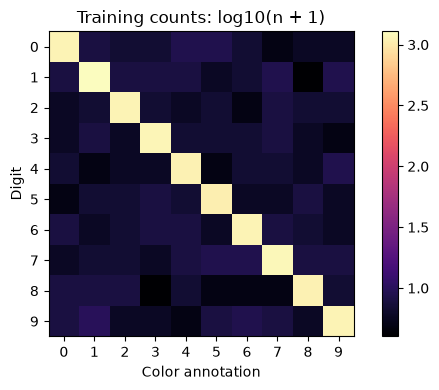

In [3]:
def group_counts(y, b, weights=None):
    table = np.zeros((10, 10), dtype=float)
    np.add.at(table, (y, b), np.ones(len(y)) if weights is None else weights)
    return table

train_counts = group_counts(y_train, b_train)
valid_counts = group_counts(y_valid, b_valid)
display(pd.DataFrame({'split': ['training', 'validation'],
                      'n': [len(y_train), len(y_valid)],
                      'aligned': [(y_train == b_train).sum(), (y_valid == b_valid).sum()],
                      'conflicting': [(y_train != b_train).sum(), (y_valid != b_valid).sum()],
                      'smallest_digit_color_cell': [train_counts.min(), valid_counts.min()]}))
if np.any(train_counts == 0):
    raise ValueError('Some digit/color combinations are absent. Increase TRAIN_LIMIT; weights cannot create missing examples.')
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(np.log10(train_counts + 1), cmap='magma')
ax.set(xlabel='Color annotation', ylabel='Digit', title='Training counts: log10(n + 1)',
       xticks=range(10), yticks=range(10))
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

## 2. Weighting rules, computed from training annotations only

Let $n_{yb}$ be the number of training images with digit $y$ and color $b$,
and $N$ the total number of training images.

* **Unweighted:** $w_i=1$.
* **Digit-only control:** $w_i=N/(10n_{y_i})$. This equalizes digit mass but
  preserves the color distribution within each digit.
* **50/50 alignment:** $w_i=N/(20n_{y_i,a_i})$, with $a_i=1[y_i=b_i]$.
  Every digit has equal mass, half aligned and half conflicting. This reduces
  the imbalance, but color and digit can still be associated: under independence
  with ten equally likely colors, the aligned fraction is **10%, not 50%**.
* **Joint digit–color correction:** $w_i^*=N/(100n_{y_i b_i})$.
  Each of the 100 digit–color combinations receives equal total mass. With full
  support, digit and annotated color are independent in the reweighted empirical
  distribution.
* **Partial correction:** $w_i(\lambda)=(1-\lambda)+\lambda w_i^*$,
  for $\lambda\in\{0.25,0.5,0.75,1\}$. This is a mixture of the observed and
  independent empirical distributions. The RF parameters never vary.

All weights have mean one. Choosing the correction strength is a choice of the
training objective, evaluated on validation data. It is not an RF hyperparameter
search. Full correction may be noisy because the few conflicting images receive
large weights. The effective sample size, $(\sum w)^2/\sum w^2$, describes this
concentration; it is not the number of distinct images or a formal accuracy bound.

For an idealized 95% aligned / 5% conflicting training distribution, full joint correction gives average weights $0.1/0.95 \approx 0.105$ to aligned images and $0.9/0.05=18$ to conflicting images: a ratio of 171. Actual per-image weights also reflect each digit–color cell count.

,min_weight,max_weight,effective_n,weighted_aligned_mass
method,,,,
unweighted,1.0000,1.0000,12000.0000,0.9555
digit_only,0.8935,1.0909,11970.9655,0.9555
alignment_50_50,0.4669,12.5000,2031.4262,0.5000
joint_0.25,0.7733,10.7500,5619.5097,0.7416
joint_0.50,0.5467,20.5000,2165.4120,0.5278
joint_0.75,0.3200,30.2500,1069.6371,0.3139
joint_1.00,0.0934,40.0000,626.0865,0.1000


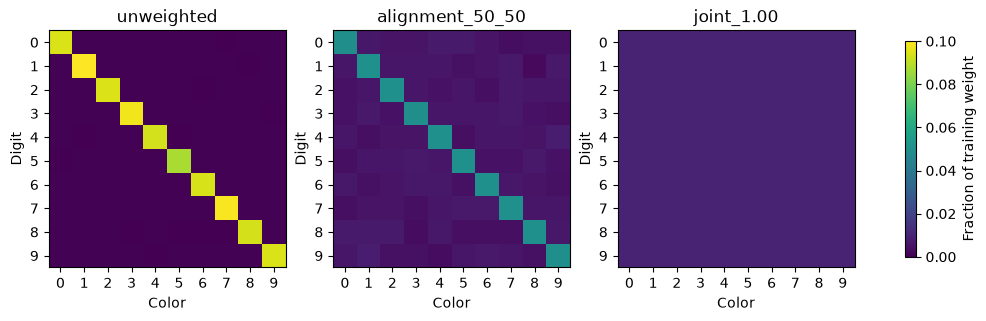

In [4]:
N = len(y_train)
digit_counts = np.bincount(y_train, minlength=10)
alignment = (y_train == b_train).astype(int)
alignment_counts = np.zeros((10, 2), dtype=int)
np.add.at(alignment_counts, (y_train, alignment), 1)
assert np.all(alignment_counts > 0)
joint_full = N / (100 * train_counts[y_train, b_train])
weights = {
    'unweighted': np.ones(N),
    'digit_only': N / (10 * digit_counts[y_train]),
    'alignment_50_50': N / (20 * alignment_counts[y_train, alignment]),
}
for strength in [0.25, 0.5, 0.75, 1.0]:
    weights[f'joint_{strength:.2f}'] = (1-strength) + strength*joint_full

weight_rows = []
for name, w in weights.items():
    assert np.isfinite(w).all() and (w > 0).all() and np.isclose(w.mean(), 1)
    weight_rows.append(dict(method=name, min_weight=w.min(), max_weight=w.max(),
                            effective_n=w.sum()**2 / (w @ w),
                            weighted_aligned_mass=w[alignment == 1].sum()/w.sum()))
weight_summary = pd.DataFrame(weight_rows).set_index('method')
display(weight_summary.round(4))
joint_mass = group_counts(y_train, b_train, weights['joint_1.00'])
assert np.allclose(joint_mass, N/100)
assert np.isclose(weight_summary.loc['joint_1.00', 'weighted_aligned_mass'], 0.1)
assert np.isclose(weight_summary.loc['alignment_50_50', 'weighted_aligned_mass'], 0.5)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, name in zip(axes, ['unweighted', 'alignment_50_50', 'joint_1.00']):
    mass = group_counts(y_train, b_train, weights[name]) / N
    im = ax.imshow(mass, vmin=0, vmax=0.1, cmap='viridis')
    ax.set(title=name, xlabel='Color', ylabel='Digit', xticks=range(10), yticks=range(10))
fig.colorbar(im, ax=axes.tolist(), label='Fraction of training weight', shrink=0.8)
plt.show()

## 3. Does weighting change the Gini reward for color?

We can measure this directly without fitting another model. For each annotated
color $c$, compute the root Gini gain of the diagnostic question $b=c$ versus
$b\ne c$. **The color annotation is used only for this diagnostic and to construct
weights; it is never an input feature of the trained forests.**

Full joint correction should make every such color-only question have zero gain
in the full reweighted training population. This does not prove that every RGB
split has zero gain: a pixel mixes shape, intensity, and color, and each bootstrap
sample is finite. A rapid impurity drop by itself also does not establish shortcut
use; it must be interpreted alongside held-out group performance.

,unweighted,digit_only,alignment_50_50,joint_0.25,joint_0.50,joint_0.75,joint_1.00
color,,,,,,,
0,0.089454,0.090206,0.019886,0.050196,0.022255,0.005550,0.0
1,0.100051,0.090135,0.018864,0.057659,0.026274,0.006740,0.0
2,0.089821,0.090567,0.019928,0.050440,0.022380,0.005586,-0.0
3,0.092649,0.090859,0.020599,0.052353,0.023375,0.005871,0.0
4,0.087969,0.090419,0.019304,0.049222,0.021763,0.005412,0.0
5,0.083162,0.090226,0.020143,0.045884,0.020013,0.004912,0.0
6,0.088786,0.090174,0.020016,0.049737,0.022015,0.005481,0.0
7,0.093259,0.089916,0.019360,0.052876,0.023690,0.005971,0.0
8,0.089033,0.091083,0.021136,0.049808,0.022017,0.005475,0.0


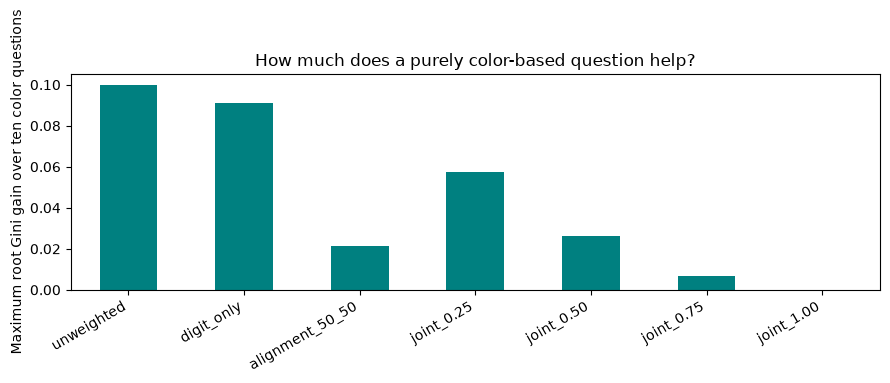

In [5]:
def gini(y, w):
    if w.sum() == 0:
        return 0.0
    p = np.bincount(y, weights=w, minlength=10) / w.sum()
    return 1 - p @ p

def binary_split_gain(y, left, w):
    total = w.sum()
    return (gini(y, w) - w[left].sum()/total*gini(y[left], w[left])
            - w[~left].sum()/total*gini(y[~left], w[~left]))

gains = pd.DataFrame({name: [binary_split_gain(y_train, b_train == c, w)
                            for c in range(10)] for name, w in weights.items()})
gains.index.name = 'color'
assert np.allclose(gains['joint_1.00'], 0, atol=1e-12)
display(gains.round(6))
ax = gains.max().plot.bar(figsize=(9, 3.5), color='teal')
ax.set(ylabel='Maximum root Gini gain over ten color questions',
       title='How much does a purely color-based question help?')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 4. Select weights on validation data

For each fixed forest, report overall accuracy, aligned and conflicting accuracy,
and their gap. To avoid a result driven by common digits, average accuracy across
digits separately within aligned and conflicting observations. The selection score
is the **smaller of these two macro accuracies**; ties prefer the first method in
the declared order. Select the best *non-baseline* weighting rule, then compare
it with the unweighted baseline, even if no weighting beats that baseline.

We also report the worst observed digit–color group and its minimum support;
small-group minima can be extremely noisy. Missing groups are excluded explicitly
and the number observed is reported. Test data do not choose weights. Initial
selection uses seed 42; three seeds later assess forest randomness for the two
preselected finalists. This is exploratory selection, not a claim of exhaustive
optimality or uncertainty over all possible training datasets.

In [6]:
def group_metrics(y, b, pred):
    correct = (pred == y)
    aligned = (y == b)
    def mean_at(mask):
        return float(correct[mask].mean()) if mask.any() else np.nan
    macro = []
    for flag in [True, False]:
        per_digit = [mean_at((y == digit) & (aligned == flag)) for digit in range(10)]
        macro.append(float(np.nanmean(per_digit)))
    per_group = []
    support = []
    for digit in range(10):
        for color in range(10):
            mask = (y == digit) & (b == color)
            if mask.any():
                per_group.append(mean_at(mask)); support.append(int(mask.sum()))
    return dict(overall=float(correct.mean()), aligned=mean_at(aligned),
                conflicting=mean_at(~aligned), gap=mean_at(aligned)-mean_at(~aligned),
                macro_aligned=macro[0], macro_conflicting=macro[1],
                robust_score=min(macro), worst_observed_group=min(per_group),
                observed_groups=len(per_group), min_group_n=min(support))

validation_rows = []
for name, w in weights.items():
    start = perf_counter()
    model = RandomForestClassifier(**RF_PARAMS, random_state=SEEDS[0])
    # Every observation remains in X_train; only its training weight changes.
    # None gives the exact ordinary-RF baseline.
    model.fit(X_train, y_train, sample_weight=None if name == 'unweighted' else w)
    metrics = group_metrics(y_valid, b_valid, model.predict(X_valid))
    validation_rows.append(dict(method=name, seconds=perf_counter()-start, **metrics))
    print(f"{name:18s} validation robust={metrics['robust_score']:.3f} "
          f"conflicting={metrics['conflicting']:.3f}", flush=True)
    del model

validation_results = pd.DataFrame(validation_rows).set_index('method')
chosen = validation_results.drop(index='unweighted').robust_score.idxmax()
display(validation_results.round(4))
print('Selected weighted method:', chosen)
print('Validation improvement over baseline:',
      validation_results.loc[chosen, 'robust_score'] - validation_results.loc['unweighted', 'robust_score'])
validation_results.to_csv(OUT/'validation_results.csv')

unweighted         validation robust=0.150 conflicting=0.162
digit_only         validation robust=0.162 conflicting=0.170
alignment_50_50    validation robust=0.513 conflicting=0.550
joint_0.25         validation robust=0.355 conflicting=0.358
joint_0.50         validation robust=0.522 conflicting=0.555
joint_0.75         validation robust=0.594 conflicting=0.629
joint_1.00         validation robust=0.656 conflicting=0.690
Selected weighted method: joint_1.00
Validation improvement over baseline: 0.5054919467787115


,seconds,overall,aligned,conflicting,gap,macro_aligned,macro_conflicting,robust_score,worst_observed_group,observed_groups,min_group_n
method,,,,,,,,,,,
unweighted,1.2308,0.9612,0.9996,0.1616,0.8380,0.9996,0.1502,0.1502,0.0,90,1
digit_only,1.0902,0.9616,0.9996,0.1703,0.8293,0.9996,0.1619,0.1619,0.0,90,1
alignment_50_50,0.7555,0.9730,0.9933,0.5502,0.4431,0.9934,0.5130,0.5130,0.0,90,1
joint_0.25,0.9168,0.9688,0.9981,0.3581,0.6400,0.9982,0.3555,0.3555,0.0,90,1
joint_0.50,0.7758,0.9726,0.9927,0.5546,0.4381,0.9928,0.5223,0.5223,0.0,90,1
joint_0.75,0.6707,0.9716,0.9881,0.6288,0.3592,0.9880,0.5938,0.5938,0.0,90,1
joint_1.00,0.3596,0.9602,0.9732,0.6900,0.2832,0.9732,0.6557,0.6557,0.0,90,1


## 5. Final held-out evaluation and seed replication

The two finalists are now frozen. Test metrics below use the test observations
with their original frequencies, never training weights. We also show the
digit–color macro accuracy (each observed group has equal evaluation importance).
No method is changed after looking at this table.

In [7]:
test_meta = manifest((ROOT/'cmnist/test').glob('*/*.png'))
X_test, y_test, b_test = read_images(test_meta)
print('Test size:', len(y_test), '| aligned fraction:', np.mean(y_test == b_test))
print('Test digit/color minimum support:', group_counts(y_test, b_test).min())

test_rows, predictions, diagnostic_models = [], {}, {}
for seed in SEEDS:
    for name in ['unweighted', chosen]:
        model = RandomForestClassifier(**RF_PARAMS, random_state=seed)
        model.fit(X_train, y_train, sample_weight=None if name == 'unweighted' else weights[name])
        pred = model.predict(X_test)
        predictions[(name, seed)] = pred
        metrics = group_metrics(y_test, b_test, pred)
        cell_acc = [np.mean(pred[(y_test == d) & (b_test == c)] == d)
                    for d in range(10) for c in range(10)
                    if np.any((y_test == d) & (b_test == c))]
        test_rows.append(dict(method=name, seed=seed, digit_color_macro=np.mean(cell_acc), **metrics))
        if seed == SEEDS[0]:
            diagnostic_models[name] = model
        print(f"{name:18s} seed={seed} test conflicting={metrics['conflicting']:.3f}", flush=True)

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))
summary_cols = ['overall', 'aligned', 'conflicting', 'gap', 'robust_score', 'digit_color_macro']
test_summary = test_results.groupby('method')[summary_cols].agg(['mean', 'std'])
display(test_summary.round(4))
test_results.to_csv(OUT/'test_results.csv', index=False)
weight_summary.to_csv(OUT/'weight_summary.csv')

Test size: 10000 | aligned fraction: 0.1006
Test digit/color minimum support: 74.0
unweighted         seed=42 test conflicting=0.182
joint_1.00         seed=42 test conflicting=0.718
unweighted         seed=43 test conflicting=0.179
joint_1.00         seed=43 test conflicting=0.731
unweighted         seed=44 test conflicting=0.184
joint_1.00         seed=44 test conflicting=0.723


,method,seed,digit_color_macro,overall,aligned,conflicting,gap,macro_aligned,macro_conflicting,robust_score,worst_observed_group,observed_groups,min_group_n
0,unweighted,42,0.2587,0.2639,1.0000,0.1816,0.8184,1.0000,0.1769,0.1769,0.0,100,74
1,joint_1.00,42,0.7374,0.7437,0.9751,0.7178,0.2573,0.9760,0.7121,0.7121,0.0,100,74
2,unweighted,43,0.2566,0.2619,1.0000,0.1793,0.8207,1.0000,0.1746,0.1746,0.0,100,74
3,joint_1.00,43,0.7505,0.7561,0.9781,0.7313,0.2469,0.9792,0.7259,0.7259,0.0,100,74
4,unweighted,44,0.2596,0.2662,1.0000,0.1841,0.8159,1.0000,0.1785,0.1785,0.0,100,74
5,joint_1.00,44,0.7421,0.7476,0.9712,0.7226,0.2486,0.9719,0.7172,0.7172,0.0,100,74


overall         aligned  ... robust_score digit_color_macro        
              mean     std    mean  ...          std              mean     std
method                              ...                                       
joint_1.00  0.7491  0.0063  0.9748  ...        0.007            0.7433  0.0066
unweighted  0.2640  0.0022  1.0000  ...        0.002            0.2583  0.0015

[2 rows x 12 columns]

Conflicting accuracy difference: +0.536; paired 95% interval [+0.526, +0.547]
This interval covers test-image sampling only, not training-set variation or weight-selection uncertainty.


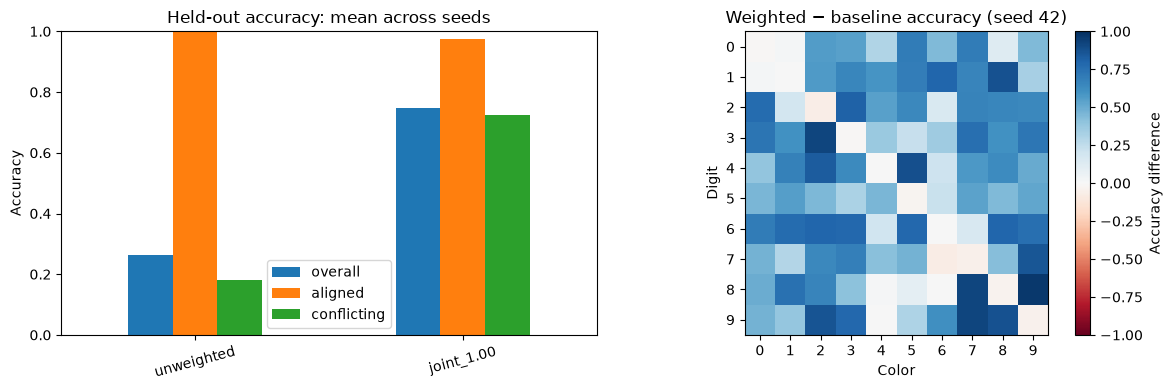

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
means = test_results.groupby('method', sort=False)[['overall', 'aligned', 'conflicting']].mean()
means.plot.bar(ax=axes[0], ylim=(0, 1), rot=15)
axes[0].set(title='Held-out accuracy: mean across seeds', ylabel='Accuracy', xlabel='')
for ax, name in zip([axes[1]], [chosen]):
    pred = predictions[(name, SEEDS[0])]
    grid = np.full((10, 10), np.nan)
    for digit in range(10):
        for color in range(10):
            mask = (y_test == digit) & (b_test == color)
            if mask.any():
                base = predictions[('unweighted', SEEDS[0])]
                grid[digit, color] = (np.mean(pred[mask] == y_test[mask]) -
                                      np.mean(base[mask] == y_test[mask]))
    im = ax.imshow(grid, cmap='RdBu', vmin=-1, vmax=1)
    ax.set(title='Weighted − baseline accuracy (seed 42)', xlabel='Color', ylabel='Digit',
           xticks=range(10), yticks=range(10))
    fig.colorbar(im, ax=ax, label='Accuracy difference')
plt.tight_layout(); plt.show()

# Paired image bootstrap, conditional on these two fitted seed-42 models.
mask = y_test != b_test
delta = ((predictions[(chosen, SEEDS[0])][mask] == y_test[mask]).astype(float) -
         (predictions[('unweighted', SEEDS[0])][mask] == y_test[mask]).astype(float))
rng = np.random.default_rng(DATA_SEED)
boot = np.array([rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(1000)])
lo, hi = np.quantile(boot, [0.025, 0.975])
print(f'Conflicting accuracy difference: {delta.mean():+.3f}; paired 95% interval [{lo:+.3f}, {hi:+.3f}]')
print('This interval covers test-image sampling only, not training-set variation or weight-selection uncertainty.')

## 6. Revisit impurity by depth

For each tree, expand the root frontier to depth $d$, retaining leaves reached
earlier, then average frontier impurity using the tree's training masses.
Unlike an unweighted average over nodes, this accounts for unequal node sizes
and keeps early terminal branches in the calculation. Curves are averaged over
all 100 trees of each seed-42 forest.

The curves describe **different training distributions**, because weights change
the effective population. They are not directly a robustness score. Read them
with the analytical color-only gain diagnostic and the held-out results; neither
impurity curves nor RGB feature-importance maps alone prove color reliance.

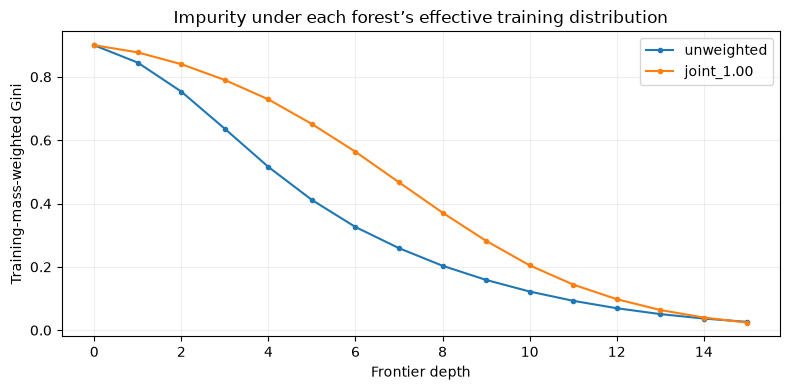

In [9]:
def frontier_gini(tree, max_depth=15):
    frontier, result = [0], []
    for depth in range(max_depth + 1):
        mass = tree.weighted_n_node_samples[frontier]
        result.append(np.average(tree.impurity[frontier], weights=mass))
        expanded = []
        for node in frontier:
            if tree.children_left[node] == -1:
                expanded.append(node)
            else:
                expanded.extend([tree.children_left[node], tree.children_right[node]])
        frontier = expanded
    return np.array(result)

fig, ax = plt.subplots(figsize=(8, 4))
for name, model in diagnostic_models.items():
    curves = np.array([frontier_gini(est.tree_) for est in model.estimators_])
    mean = curves.mean(axis=0)
    ax.plot(range(len(mean)), mean, marker='.', label=name)
ax.set(xlabel='Frontier depth', ylabel='Training-mass-weighted Gini',
       title='Impurity under each forest’s effective training distribution')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 7. Interpret the experiment

The cell below derives its statements from this run. A smaller aligned/conflicting
gap is useful only if conflicting accuracy improves: destroying aligned accuracy
can also shrink the gap. Full correction's zero gain for annotated color is an
empirical distribution property, not a guarantee of invariance of the fitted RF.

Also inspect `worst_observed_group`: the average can improve while individual digit/color combinations still fail completely. A reduction in average error is insufficient to call the forest unbiased.

In [10]:
avg = test_results.groupby('method')[summary_cols].mean()
baseline, weighted = avg.loc['unweighted'], avg.loc[chosen]
change = weighted.conflicting - baseline.conflicting
direction = 'improved' if change > 0 else ('decreased' if change < 0 else 'was unchanged')
display(Markdown(f'''
**Selected weighting rule:** `{chosen}` (validation only).

Across {len(SEEDS)} forest seeds, conflicting test accuracy {direction} from
**{baseline.conflicting:.1%} to {weighted.conflicting:.1%}** ({change*100:+.1f} percentage points).
Aligned accuracy changed from **{baseline.aligned:.1%} to {weighted.aligned:.1%}**,
and overall test accuracy from **{baseline.overall:.1%} to {weighted.overall:.1%}**.
The signed aligned–conflicting gap changed from **{baseline.gap:.1%} to {weighted.gap:.1%}**.
The selected rule has effective training size **{weight_summary.loc[chosen, 'effective_n']:.0f}**
out of **{N}** distinct observations.

These results support a conclusion about this CMNIST split and this weighting
procedure. They do not establish that all color dependence has disappeared.
'''))

metadata = dict(train_limit=TRAIN_LIMIT, train_n=N, full_train_n=len(train_all),
                validation_n=len(y_valid), test_n=len(y_test), data_seed=DATA_SEED,
                seeds=SEEDS, rf_parameters=RF_PARAMS, selected_weighting=chosen,
                python=platform.python_version(), sklearn=sklearn.__version__,
                numpy=np.__version__, pandas=pd.__version__,
                paired_conflicting_delta=float(delta.mean()),
                paired_conflicting_interval=[float(lo), float(hi)])
(OUT/'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Saved tables and run configuration to:', OUT)

Saved tables and run configuration to: C:\Users\Marco\Developer\RF-SpuriousCorrelations\rf_mitigation_results


<IPython.core.display.Markdown object>

### What follows from weights, and what remains unresolved?

1. **Why it can work:** weights change the effective label–color relationship,
   so training has less incentive to use color as a shortcut. No change to the
   Gini formula or RF architecture is required.
2. **Why digit weights alone are insufficient:** they do not change
   $P(b\mid y)$. A nearly digit-balanced dataset can still be strongly biased.
3. **Why 50/50 is incomplete:** with ten colors, half aligned is still far from
   independence. Joint correction targets all 100 combinations explicitly.
4. **Why it can fail:** rare examples may be unrepresentative or mislabeled.
   High weights can amplify those problems, cannot create absent combinations,
   and cannot recover shape information that is missing from input features.
5. **Scope:** this uses known training color annotations. If the spurious
   attribute is unknown, these exact weights cannot be computed without first
   identifying suitable groups. Validation also needs enough conflicting cases.
6. **Next experiment:** rerun the predeclared procedure on the full training set
   (`TRAIN_LIMIT=None`) and eventually independent data splits. Treat the test set
   as already inspected; confirm new hypotheses with fresh held-out data. A
   controlled same-digit/different-color evaluation would provide stronger direct
   evidence of invariance than group accuracy alone.

**Answer to the research question:** training weights are a concrete intervention
on the Random Forest's learning procedure. They can reduce the biased distribution's
influence; the measured performance and weight concentration determine whether
that intervention is useful in this experiment. Prevention is not guaranteed.

## Follow-up audit: which groups still fail?

Recorded follow-up for the configuration above (data seed 2026; RF seeds 42, 43,
44; full joint correction). Accuracies below are averages across the same three
seeds. The 55,000-image check keeps every RF parameter and the weighting rule
fixed and increases the available training data. It is a follow-up diagnostic on
an already inspected test set, not a fresh confirmatory test or a new round of
weight selection. To reproduce its training setup, set `TRAIN_LIMIT=None` and
rerun the notebook.

| Digit | Color | Training examples (12k / 55k) | Accuracy (12k) | Accuracy (55k) |
|---|---|---:|---:|---:|
| 9 | green (4) | 4 / 20 | 0.0% | 2.3% |
| 8 | blue (6) | 4 / 18 | 2.1% | 33.0% |
| 8 | green (4) | 6 / 29 | 4.1% | 35.6% |
| 8 | cyan (5) | 4 / 20 | 9.9% | 36.0% |
| 2 | blue (6) | 4 / 18 | 14.8% | 49.8% |
| 4 | blue (6) | 6 / 27 | 18.8% | 59.4% |

Green 9s scored zero in every seed in the 12,000-image run (100 distinct test
images); using all training images raised their mean accuracy only to 2.3%.
The six rows shown are the groups below 20% in the exploratory subset; 16 groups
were below 50%. The predominant seed-42 prediction for each of these six groups
was the digit associated with the color.

The full-data weighted forest achieved **84.2% overall**,
**82.6% conflicting**, and
**98.3% aligned** accuracy across the three seeds. This
improves on the subset, but still falls short of the original 97% reference.

That reference also changes the representation: `load_images_unbiased` in
`RF_bias.ipynb` converts RGB to grayscale and sets every nonzero pixel to 255.
It removes color before training and supplies a binary shape mask. It is not a
comparison that changes only the sampling bias.

Weights can increase the influence of a rare group, but cannot create new digit
shapes: green 9s have only 20 distinct training images even in the full dataset.
The zero color-annotation-only Gini gain established above does not rule out
color/shape interactions in RGB splits.

A next weight-only experiment is cross-fitted error-aware reweighting: obtain
held-out predictions on folds of the training set, upweight consistently hard
examples or groups with bounded weight updates, and refit the same forest. Choose
weight updates and stopping on validation data, never on the test failures listed
here. This is a proposed experiment, not a demonstrated route to 97%. Ordinary
training errors are unsuitable because flexible trees can fit their training
examples. The current validation set also misses 10 digit/color groups, so
worst-group validation estimates need particular care.

Per-group tables and full-data results are saved under `rf_mitigation_results/`.
